## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Claire Curzan

**Date:** 10/21/2026

Total tokens: 276949
Unique tokens: 48691
[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]
count    48691.000000
mean         5.687889
std         27.717476
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max       1365.000000
dtype: float64
Share of tokens that appear only once: 0.604


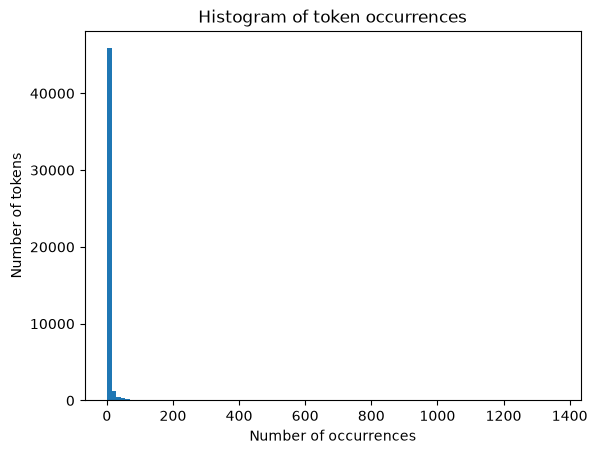

In [7]:
# Your Phase 1 solution to the problem goes here.
# Q1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

counts = [count for token, count in token_freq]

print("Total tokens:", len(all_tokens))
print("Unique tokens:", len(counts))
print(token_freq[:10])

counts_series = pd.Series(counts)
print(counts_series.describe())
print("Share of tokens that appear only once:", round((counts_series == 1).mean(), 3))

plt.hist(counts, bins=100)
plt.xlabel("Number of occurrences")
plt.ylabel("Number of tokens")
plt.title("Histogram of token occurrences")
plt.show()

Q1) Plot a histogram of the occurrences of tokens. What do you notice about the frequency of occurrence of different tokens? How does it look?

The histogram looks extremely right-skewed: a few tokens show up very often, but most tokens are rare. There are 276,949 tokens in total and only 48,691 unique words. Almost all of the tokens fall in the first bar which goes above 40,000 on the y-axis, and the rest of the plot is basically flat out to the max of 1,365. The summary show this right-skew: the median is 1 and the 75th percentile is 2, so most words show up only once or twice, and 60.4% of the unique tokens appear exactly once.

The frequency of occurrence is very uneven across tokens. A handful of words are used a lot: "new" appears 1,365 times, and "date", "get" and "please" each appear more than 1,000 times. These common words pull the mean up to 5.69 even though the median is 1, which also explains the large standard deviation of 27.7.

In [3]:
# Q2
df = pd.read_parquet('data/Phishing_clean.parquet')

y = df['Email Type']
X = df.drop('Email Type', axis=1)

# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)

reg = LinearRegression().fit(X_train, y_train)

print("Train R^2:", round(reg.score(X_train, y_train), 3))
print("Test R^2: ", round(reg.score(X_test, y_test), 3))

coef = pd.DataFrame({'variable': reg.feature_names_in_, 'coefficient': reg.coef_})
coef['abs_coef'] = np.abs(coef['coefficient'])
coef.sort_values('abs_coef', ascending=False).head(15)

Train R^2: 0.768
Test R^2:  0.659


,variable,coefficient,abs_coef
1504,background-image:,-0.891476,0.891476
740,localized,0.815698,0.815698
1406,"helvetica,",0.717349,0.717349
2362,thermal,0.706216,0.706216
906,aging,0.622411,0.622411
2566,transcript,0.578132,0.578132
2559,april's,-0.546313,0.546313
1494,retrieving,-0.527824,0.527824
818,cnet,-0.510492,0.510492
2657,zdnet,-0.503465,0.503465


Q2) 1. Perform an 80/20 train-test split of the data. 2. Run a regression of y on the one-hot-encoded emails. What is the R^2 on the test set? On the training set? 3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

The R^2 is 0.768 on the training set and 0.659 on the test set. That means the model explains about 77% of the variation in whether an email is a scam for the data it was trained on, but only about 66% for new emails it hasn’t seen. The test R^2 is about 0.11 lower than the training R^2, so the model is overfitting somewhat, which makes sense with 2,711 word variables.

The words with the largest coefficients in absolute value are “background-image:” (-0.891), “localized” (0.816), “helvetica,” (0.717), “thermal” (0.706) and “aging” (0.622). A positive coefficient pushes the prediction toward a scam (Email Type = 1), so “localized”, “helvetica,”, “thermal”, “aging”, “transcript” and “xanaax” push toward phishing. A negative coefficient pushes toward a normal email, so “background-image:”, “april’s”, “retrieving”, “cnet”, “zdnet” and “arial,” push away from phishing. Many of the top words are formatting/code tokens (“background-image:”, “helvetica,”, “arial,”, “{text-decoration:”) rather than regular words, and none of them are among the most common words from Q1 like “new” or “please”. This was kinda suprising to me that words that most strongly influence the predictions are not the obvious scam words I expected.

Variance explained: [0.0111 0.0086]


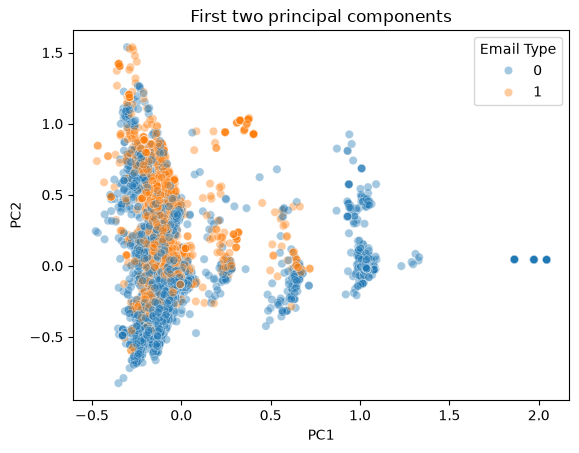

In [4]:
# Q3
pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)

print("Variance explained:", pca.explained_variance_ratio_.round(4))

pca_df = pd.DataFrame({'PC1': X_pca[:, 0], 'PC2': X_pca[:, 1], 'Email Type': y})

sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type', alpha=0.4)
plt.title("First two principal components")
plt.show()

Q3) Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

Yes, there are some patterns, but the two classes overlap a lot. The first two principal components only explain 1.11% and 0.86% of the variance, so together they capture less than 2% of the information in the 2,711 token columns. That’s why most of the emails are bunched together in one big cluster between about -0.5 and 0.25 on PC1, with phishing and non-phishing points mixed together.

Inside that main cluster, the phishing emails (orange) tend to sit higher on PC2, mostly between about 0 and 1.5. The non-phishing emails (blue) go lower, and almost all the points below about -0.4 on PC2 are blue. Off to the right there are separate vertical clusters around PC1 = 0.5, 1.0 and 2.0. The ones near 1.0 and 2.0 are basically all non-phishing, and the one near 0.5 is mixed. There’s also a small group of phishing emails around PC1 = 0.3 and PC2 = 1.0. PC2 seems to separate the classes a little, and very high PC1 values mostly mean a normal email, but two components aren’t enough to cleanly separate phishing emails from normal emails.

In [5]:
# Q4
pca_big = PCA(n_components=2610).fit(X_train)
Z_train = pca_big.transform(X_train)
Z_test = pca_big.transform(X_test)

print("Variance retained:", round(pca_big.explained_variance_ratio_.sum(), 4))

reg_pca = LinearRegression().fit(Z_train, y_train)

print("Train R^2:", round(reg_pca.score(Z_train, y_train), 3))
print("Test R^2: ", round(reg_pca.score(Z_test, y_test), 3))

Variance retained: 0.9998
Train R^2: 0.767
Test R^2:  0.66


Q4) Run a linear regression of y on the first 2,610 principal components of X. What is the R^2 on the training and test sets? How does this performance compare to the linear regression?


The R^2 of the regression on the first 2,610 principal components is 0.767 on the training set and 0.66 on the test set. This is almost exactly the same as the regular linear regression from Q2, which had 0.768 on the training set and 0.659 on the test set. The training R^2 went down by 0.001 and the test R^2 went up by 0.001, so the performance is pretty much the same. The gap between training and test R^2 is still  0.11, so the PCA model overfits by about the same amount as the original regression. This makes sense because 2,610 components keep about 99.98% of the variance in X. The regression gets almost the same information while using about 100 fewer variables.

Q5) Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

An advantage to using PCA is that it helps turn the word columns into new variables that are uncorrelated with each other. Many of the 2,711 word columns overlap because some words tend to show up together. When variables overlap like that, the regression has trouble deciding how much credit each word gets, which is why Q2 gave big coefficients to odd tokens like “background-image:”. PCA combines the overlapping words into new variables with no overlap which gets rid of that problem, and it ranks them from most important to least important. In Q4, keeping 2,610 components still kept 99.98% of the information (so the model was basically the same regression and the overfitting didn’t change all that much), and the train-test gap was still about 0.11. The real benefit for overfitting comes when you keep a much smaller number of components, because then the model has far fewer variables that could fit noise.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 76ff3706d3c759d6acd2050e8cdacb0dcbb000dc
- **AI tool and model used:** Claude Opus 5.5

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [6]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]